# Identificação de M2 com Gaia DR3

Neste exemplo usamos o AI-Scope para buscar estrelas ao redor de M2 e identificar sua população a partir de uma sobredensidade no espaço de movimentos próprios.

A posição do aglomerado é conhecida, mas seu movimento próprio não é fornecido ao método.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import adss

cl = adss.ADSSClient(
    base_url="https://ai-scope.cbpf.br/",
)


## Consulta ao Gaia DR3

Em `public.gaia_dr3`, selecione até **50.000** fontes dentro de `RADIUS_DEG` de (`CENTER_RA`, `CENTER_DEC`). Retorne ID, coordenadas, paralaxe e erro, movimentos próprios e erros, fotometria G/BP/RP, `bp_rp`, `ruwe` e a distância angular `radius_deg` calculada por `dist`. Exija movimentos próprios e magnitudes G/BP/RP presentes e `phot_g_mean_mag < 19`. `cone` faz o corte espacial no servidor; `dist` devolve graus.


In [ ]:
CENTER_RA = 323.3626
CENTER_DEC = -0.8233
RADIUS_DEG = 1.0

query = None  # Complete a consulta AstroQL do enunciado.
if query is None:
    raise NotImplementedError("Complete query; veja outputs/respostas.txt após tentar.")

gaia = cl.query_and_wait(query_text=query, mode="astroql").data

print(f"{len(gaia):,} fontes")
gaia.head()


## Seleção de qualidade


In [3]:
clean = gaia[
    (gaia.ruwe < 1.4) &
    (gaia.pmra_error < 1.0) &
    (gaia.pmdec_error < 1.0)
].copy()

print(f"{len(clean):,} fontes após os cortes")


14,309 fontes após os cortes


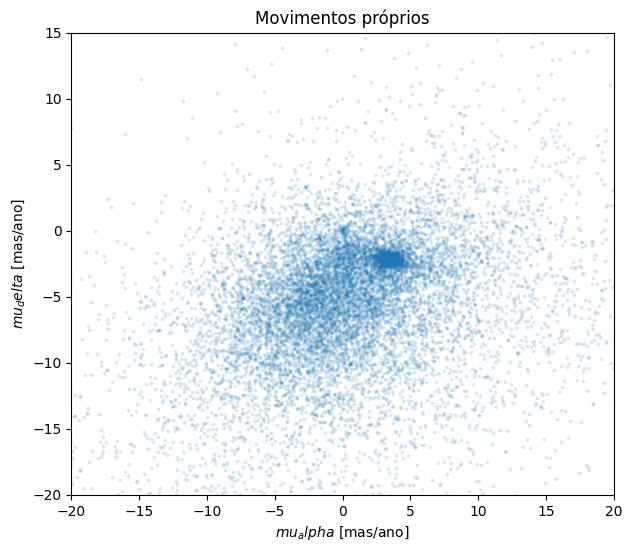

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(clean.pmra, clean.pmdec, s=3, alpha=0.12)
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 15)
ax.set_xlabel(r"$mu_alpha$ [mas/ano]")
ax.set_ylabel(r"$mu_delta$ [mas/ano]")
ax.set_title("Movimentos próprios")
plt.show()


## Região central e campo de controle

A região central contém uma contribuição maior do aglomerado. Uma região externa é usada para estimar a distribuição cinemática das estrelas de campo.


In [6]:
core = clean[clean.radius_deg < 0.05].copy()

field = clean[
    (clean.radius_deg >= 0.5) &
    (clean.radius_deg <= 1.0)
].copy()

print(f"Centro: {len(core):,}")
print(f"Campo:  {len(field):,}")


Centro: 1,406
Campo:  8,942


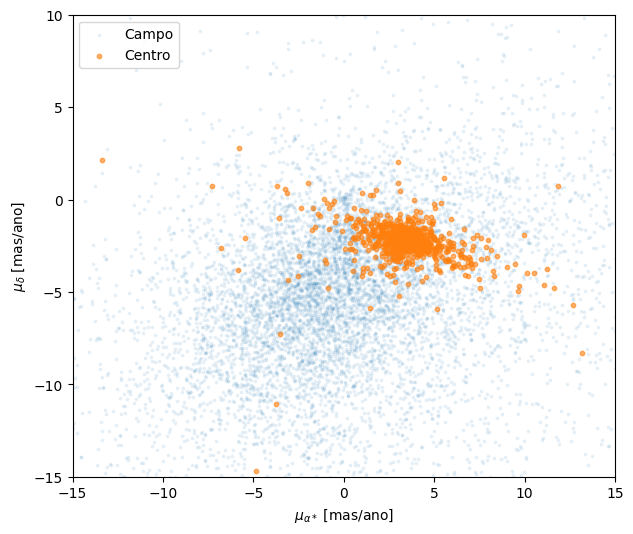

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(field.pmra, field.pmdec, s=3, alpha=0.08, label="Campo")
ax.scatter(core.pmra, core.pmdec, s=10, alpha=0.6, label="Centro")

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 10)
ax.set_xlabel(r"$\mu_{\alpha*}$ [mas/ano]")
ax.set_ylabel(r"$\mu_{\delta}$ [mas/ano]")
ax.legend()
plt.show()


## Sobredensidade cinemática

`scipy.stats.gaussian_kde` estima uma **densidade suavizada** no plano (`pmra`, `pmdec`): coloca um núcleo gaussiano em cada ponto e soma as contribuições. Não ajusta uma única gaussiana ao aglomerado. `np.vstack` organiza as duas coordenadas em linhas, como a função espera. A largura de suavização é escolhida automaticamente e pode apagar subestruturas; compare o resultado com o diagrama de dispersão. Aqui `kde_core(xy)` e `kde_field(xy)` avaliam as duas densidades nas mesmas posições. O logaritmo da razão mede excesso relativo, não probabilidade de associação.

Referência: [SciPy `gaussian_kde`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gaussian_kde.html).


In [9]:
pm_min, pm_max = -20, 20
pd_min, pd_max = -20, 15

core_pm = core[
    core.pmra.between(pm_min, pm_max) &
    core.pmdec.between(pd_min, pd_max)
]

field_pm = field[
    field.pmra.between(pm_min, pm_max) &
    field.pmdec.between(pd_min, pd_max)
]

kde_core = gaussian_kde(np.vstack([core_pm.pmra, core_pm.pmdec]))
kde_field = gaussian_kde(np.vstack([field_pm.pmra, field_pm.pmdec]))

xy = np.vstack([clean.pmra, clean.pmdec])

p_core = kde_core(xy)
p_field = kde_field(xy)

floor = np.percentile(p_field[p_field > 0], 1)

clean["kinematic_excess"] = np.log10(
    (p_core + floor) / (p_field + floor)
)


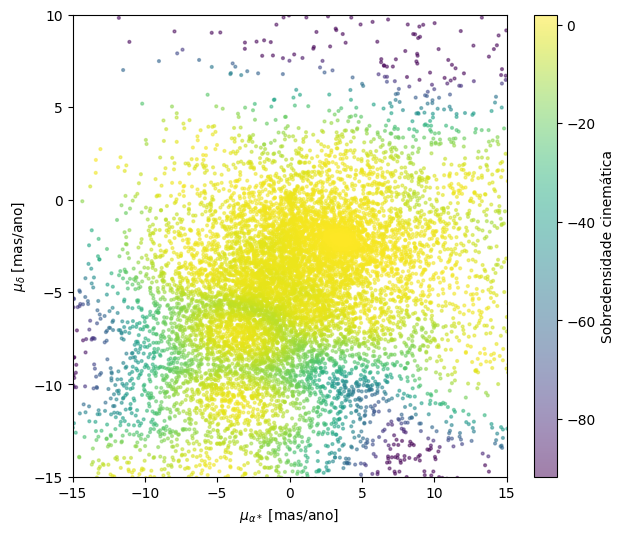

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))

sc = ax.scatter(
    clean.pmra,
    clean.pmdec,
    c=clean.kinematic_excess,
    s=4,
    alpha=0.5
)

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 10)
ax.set_xlabel(r"$\mu_{\alpha*}$ [mas/ano]")
ax.set_ylabel(r"$\mu_{\delta}$ [mas/ano]")

plt.colorbar(sc, label="Sobredensidade cinemática")
plt.show()


## Candidatos a membros


In [12]:
threshold = clean.kinematic_excess.quantile(0.975)

cluster = clean[
    clean.kinematic_excess >= threshold
].copy()

print(f"Limite: {threshold:.3f}")
print(f"Candidatos: {len(cluster):,}")


Limite: 1.984
Candidatos: 358


### Distribuição espacial


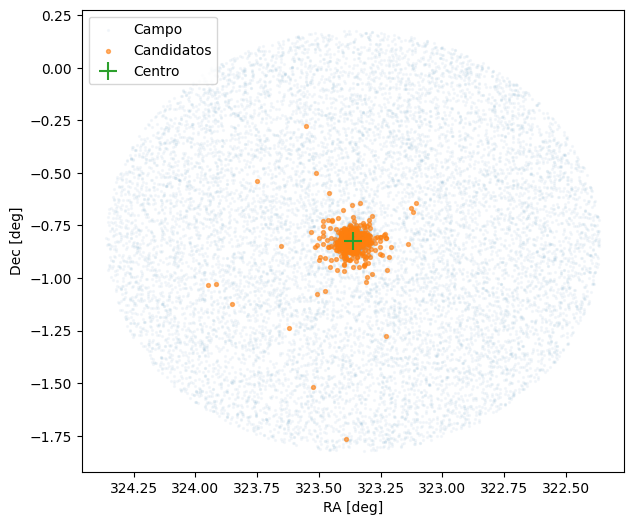

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(clean.ra, clean.dec, s=2, alpha=0.04, label="Campo")
ax.scatter(cluster.ra, cluster.dec, s=8, alpha=0.6, label="Candidatos")

ax.scatter(CENTER_RA, CENTER_DEC, marker="+", s=150, label="Centro")

ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.invert_xaxis()
ax.legend()

plt.show()


### Diagrama cor-magnitude

No diagrama cor–magnitude, `bp_rp` é a cor (diferença entre magnitudes Gaia BP e RP). O eixo de G é invertido porque objetos mais brilhantes têm magnitude menor.


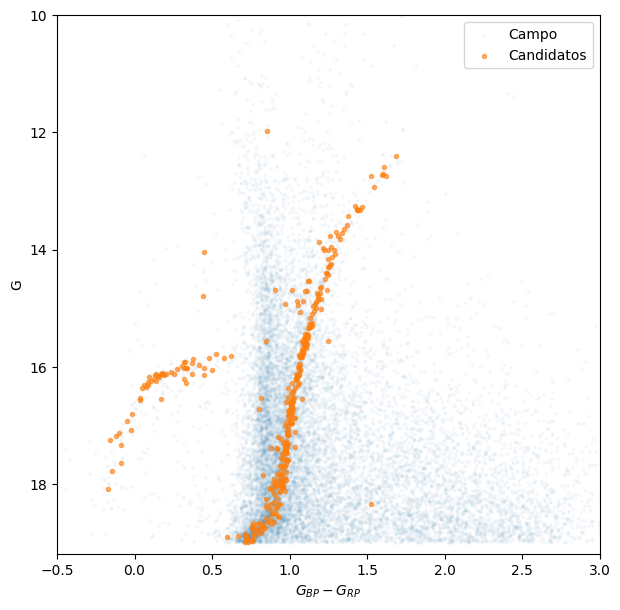

In [14]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    clean.bp_rp,
    clean.phot_g_mean_mag,
    s=3,
    alpha=0.03,
    label="Campo"
)

ax.scatter(
    cluster.bp_rp,
    cluster.phot_g_mean_mag,
    s=9,
    alpha=0.6,
    label="Candidatos"
)

ax.set_xlim(-0.5, 3)
ax.set_ylim(19.2, 10)
ax.set_xlabel(r"$G_{BP}-G_{RP}$")
ax.set_ylabel("G")
ax.legend()

plt.show()


## Catálogo final

Salvamos apenas os objetos selecionados como candidatos do aglomerado. Este catálogo pode ser usado diretamente nos próximos exemplos, incluindo o crossmatch com DESI.


In [15]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

cluster = cluster[
    [
        "source_id",
        "ra",
        "dec",
        "radius_deg",
        "pmra",
        "pmdec",
        "pmra_error",
        "pmdec_error",
        "parallax",
        "parallax_error",
        "phot_g_mean_mag",
        "phot_bp_mean_mag",
        "phot_rp_mean_mag",
        "bp_rp",
        "ruwe",
        "kinematic_excess",
    ]
].sort_values("kinematic_excess", ascending=False)

cluster.to_csv("outputs/cluster_1.csv", index=False)

print(f"{len(cluster):,} objetos salvos em outputs/cluster_1.csv")
cluster.head()


358 objetos salvos em outputs/cluster_1.csv


,source_id,ra,dec,radius_deg,pmra,pmdec,pmra_error,pmdec_error,parallax,parallax_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,ruwe,kinematic_excess
6764,2686840521431628288,323.324139,-0.880722,0.069110,3.535957,-2.173133,0.114538,0.073543,0.008011,0.113313,17.320658,17.716633,16.747751,0.968882,0.979177,2.002077
6423,2686842033259327104,323.216615,-0.902025,0.165845,3.540397,-2.169961,0.119509,0.083477,-0.033886,0.115138,17.649788,18.056982,17.079865,0.977118,1.053021,2.002068
6951,2686841208630066176,323.323723,-0.850133,0.047235,3.523109,-2.172632,0.082432,0.045770,-0.009831,0.066133,16.312115,16.360470,16.273584,0.086885,1.005163,2.002033
6650,2686843579447556992,323.253369,-0.887782,0.126833,3.523987,-2.174720,0.123127,0.080571,0.130173,0.114084,17.476366,17.879677,16.900747,0.978930,1.036951,2.002006
9106,2686850245241277696,323.344394,-0.804620,0.026083,3.551845,-2.166595,0.198749,0.100412,0.172955,0.130352,17.393589,17.130636,16.252893,0.877743,1.163365,2.001873
